<a href="https://colab.research.google.com/github/itunuoluwawizard/Itunuoluwa-Akanmu-Quality-Wizards/blob/main/Group_40_Hotel_Booking_Cancellations_Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group 40 — Hotel Booking Cancellations

**Data Science Project | Submission Notebook**

**Student:** Itunuoluwa Michael Akanmu  
**Dataset:** Hotel Booking Demand (Hotel Booking Cancellations)  
**Source:** Kaggle — `jessemostipak/hotel-booking-demand`  
**Target:** `is_canceled` (0 = not canceled; 1 = canceled)

## Project objective

This project examines hotel booking behaviour and cancellation patterns, identifies booking profiles through clustering, and develops classification models to estimate cancellation risk. The analysis connects the results to practical decisions in booking management, room allocation and operational planning.

**Reproducibility:** Run the notebook from top to bottom in a fresh Google Colab runtime. The dataset is retrieved through `kagglehub`. If Kaggle requests authentication, configure the Kaggle API credentials in Colab before running the download cell. All randomised procedures use a fixed seed where applicable.

## Submission summary

| Item | Entry |
|---|---|
| Group number | 40 |
| Full name | Itunuoluwa Michael Akanmu |
| Dataset | Hotel Booking Demand / Hotel Booking Cancellations |
| Depth track | Clustering, classification and imbalance evaluation |
| Team members | Onum Israel Amedu; Wofai Willie IKPI; Awolesi Samuel Ebunoluwa; Egberibin Donald Ifiemi; Adegbayi Adewale Benjamin; Enyi Ogbonnaya Uneke; Okolie Paulina; Allen Chimenyime Ukelabuchi |
| Target variable | `is_canceled` |
| Leakage columns excluded | `reservation_status`, `reservation_status_date` |
| Sampling | Full dataset retained; no sampling |
| Final model and metrics | Generated in the final summary cell after execution |

> **Execution note:** The final model metrics are generated from the actual rerun. Do not copy metrics from an earlier notebook run because the cleaning and preprocessing workflow has been revised.

# Part 1 — Data Foundation

## 1.1 Environment setup

The required libraries are installed or imported before the data is loaded. `kagglehub` is used so the dataset can be retrieved programmatically rather than relying on a manually uploaded local file.

In [17]:
%pip -q install kagglehub

In [18]:
import os
import time
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
run_start = time.perf_counter()

print("Core libraries imported successfully.")

Core libraries imported successfully.


## 1.2 Dataset import

The dataset is downloaded from the assigned Kaggle source using `kagglehub`. The file path is checked before loading to confirm that the expected CSV is available.

In [19]:
import kagglehub

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
file_path = os.path.join(path, "hotel_bookings.csv")

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Expected dataset was not found: {file_path}")

df_raw = pd.read_csv(file_path)
df = df_raw.copy()

print("Dataset path:", file_path)
print("Initial shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Dataset path: /kaggle/input/hotel-booking-demand/hotel_bookings.csv
Initial shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1.3 Dataset size and sampling decision

The dataset contains more than 100,000 observations, so the assignment permits either full-data analysis or stratified sampling. The full dataset is retained because it is manageable for the selected analyses in Colab and retaining all observations avoids discarding potentially useful booking patterns. No sampling is applied; therefore, a sample size or sampling random state is not required.

In [20]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("Target class proportions before cleaning:")
print((df["is_canceled"].value_counts(normalize=True).sort_index() * 100).round(2))

Rows: 119,390
Columns: 32
Target class proportions before cleaning:
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


## 1.4 Store the source data in SQLite

The original dataset is written to a SQLite database. SQL queries are then used to answer business questions directly from the relational table. The raw table is retained separately from the cleaned modelling dataset.

In [21]:
conn = sqlite3.connect("hotel_bookings_group40.db")
df_raw.to_sql("hotel_bookings_raw", conn, if_exists="replace", index=False)

print("Raw dataset loaded into SQLite.")
pd.read_sql_query("SELECT * FROM hotel_bookings_raw LIMIT 5;", conn)

Raw dataset loaded into SQLite.


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,None,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,None,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,None,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1.5 SQL analysis

The first query compares cancellation rates by hotel type. This helps establish whether cancellation exposure differs between City Hotels and Resort Hotels. The cancellation rate is calculated as the average of the binary target multiplied by 100.

In [22]:
query1 = """
SELECT
    hotel,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings_raw
GROUP BY hotel
ORDER BY cancellation_rate_percent DESC;
"""
result1 = pd.read_sql_query(query1, conn)
display(result1)

,hotel,total_bookings,canceled_bookings,cancellation_rate_percent
0,City Hotel,79330,33102,41.73
1,Resort Hotel,40060,11122,27.76


**Interpretation — Query 1:** In the source data, City Hotel records 79,330 bookings and 33,102 cancellations, a cancellation rate of 41.73%. Resort Hotel records 40,060 bookings and 11,122 cancellations, a rate of 27.76%. City Hotel therefore has higher observed cancellation exposure. This difference warrants investigation of booking mix, lead time and channel composition; it does not by itself establish the cause of cancellations.

The second query compares cancellation rates across market segments. Both booking volume and cancellation rate are displayed because a high rate in a very small segment may be less operationally important than a moderately high rate in a large segment.

In [23]:
query2 = """
SELECT
    market_segment,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings_raw
GROUP BY market_segment
ORDER BY cancellation_rate_percent DESC;
"""
result2 = pd.read_sql_query(query2, conn)
display(result2)

,market_segment,total_bookings,canceled_bookings,cancellation_rate_percent
0,Undefined,2,2,100.00
1,Groups,19811,12097,61.06
2,Online TA,56477,20739,36.72
3,Offline TA/TO,24219,8311,34.32
4,Aviation,237,52,21.94
5,Corporate,5295,992,18.73
6,Direct,12606,1934,15.34
7,Complementary,743,97,13.06


**Interpretation — Query 2:** Groups has a cancellation rate of 61.06% across 19,811 bookings. Online TA records 36.72% across 56,477 bookings, while Offline TA/TO records 34.32% across 24,219 bookings. The Undefined segment has a 100% rate but only two bookings, so that percentage is not a reliable basis for a policy decision. Group bookings merit investigation because the segment has both a high rate and meaningful volume. Online and offline travel-agency channels also warrant monitoring because of their booking volumes.

The third query compares cancellations across deposit types. This is a descriptive association; it should not be interpreted as proof that a deposit type causes cancellation.

In [24]:
query3 = """
SELECT
    deposit_type,
    COUNT(*) AS total_bookings,
    SUM(is_canceled) AS canceled_bookings,
    ROUND(AVG(is_canceled) * 100, 2) AS cancellation_rate_percent
FROM hotel_bookings_raw
GROUP BY deposit_type
ORDER BY cancellation_rate_percent DESC;
"""
result3 = pd.read_sql_query(query3, conn)
display(result3)

,deposit_type,total_bookings,canceled_bookings,cancellation_rate_percent
0,Non Refund,14587,14494,99.36
1,No Deposit,104641,29694,28.38
2,Refundable,162,36,22.22


**Interpretation — Query 3:** Non Refund bookings show a 99.36% cancellation rate (14,494 cancellations out of 14,587 bookings), compared with 28.38% for No Deposit bookings and 22.22% for Refundable bookings. The Non Refund result is unusual and should be validated against the dataset's booking definitions and records before any deposit-policy change is proposed. It is safer to report this as an observed association requiring investigation rather than conclude that non-refundable deposits increase cancellations.

## 1.6 Exploratory data analysis (EDA)

The dataset's dimensions and data types are inspected to understand its structure and guide cleaning and feature preparation.

In [25]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (119390, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  i

### Missing-value assessment

Missing values are examined by column before selecting a treatment. A blanket imputation method is avoided because the amount and likely meaning of missingness differ between variables.

In [26]:
missing_summary = (
    df.isna().sum()
      .loc[lambda s: s > 0]
      .sort_values(ascending=False)
      .to_frame("missing_count")
)
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
display(missing_summary)

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### Target distribution

The target distribution is examined to understand the proportion of canceled and non-canceled bookings. This informs the choice of stratified splitting and the use of class-sensitive evaluation metrics.

,count,percentage
Not canceled (0),75166,62.96
Canceled (1),44224,37.04


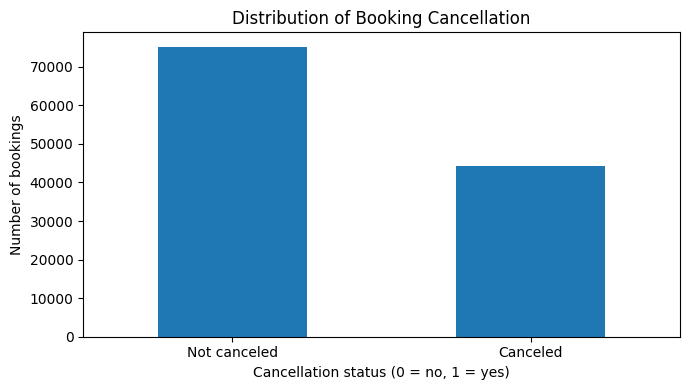

In [27]:
target_summary = pd.DataFrame({
    "count": df["is_canceled"].value_counts().sort_index(),
    "percentage": df["is_canceled"].value_counts(normalize=True).sort_index() * 100
})
target_summary.index = ["Not canceled (0)", "Canceled (1)"]
display(target_summary.round(2))

ax = df["is_canceled"].value_counts().sort_index().plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribution of Booking Cancellation")
ax.set_xlabel("Cancellation status (0 = no, 1 = yes)")
ax.set_ylabel("Number of bookings")
ax.set_xticklabels(["Not canceled", "Canceled"], rotation=0)
plt.tight_layout()
plt.show()

### Numerical feature distributions

Five numerical features are selected because they represent booking timing, room price, stay duration and customer requirements. Histograms are used to inspect skewness and unusual values before modelling.

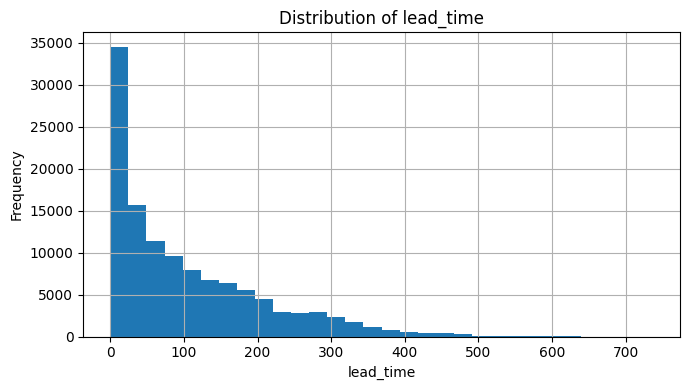

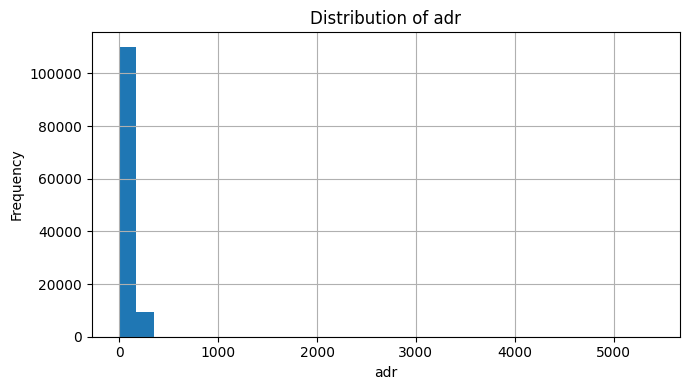

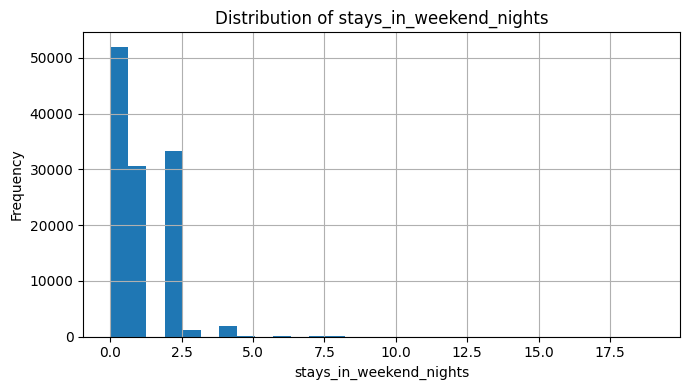

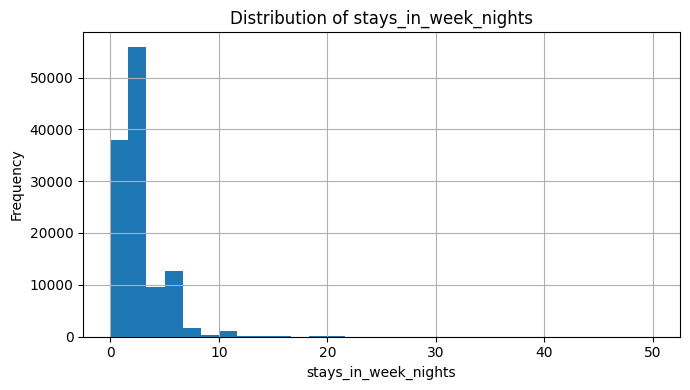

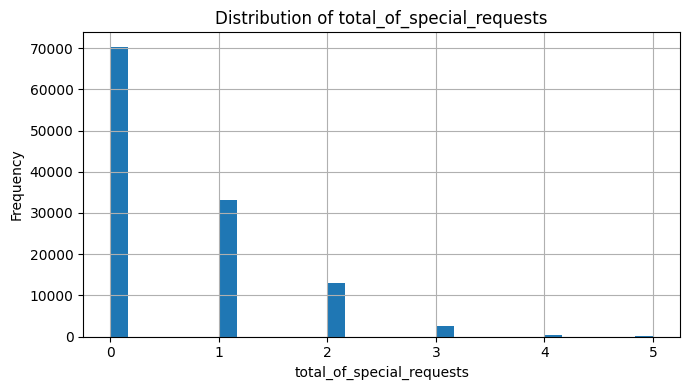

In [28]:
eda_features = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_of_special_requests"
]

for feature in eda_features:
    plt.figure(figsize=(7, 4))
    df[feature].hist(bins=30)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# Part 2 — Feature Engineering and Encoding

## 2.1 Data cleaning

Exact duplicate rows are removed once from the original dataset, before any columns are dropped. This avoids incorrectly treating records as duplicates merely because distinguishing columns were removed later. The two reservation outcome fields are excluded because they disclose the eventual reservation status and would leak information into a model predicting cancellation.

In [29]:
print("Exact duplicate rows before removal:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after exact duplicate removal:", df.shape)
print("Remaining exact duplicates:", df.duplicated().sum())

leakage_columns = ["reservation_status", "reservation_status_date"]
df = df.drop(columns=leakage_columns)
print("Leakage columns removed:", leakage_columns)

Exact duplicate rows before removal: 31994
Shape after exact duplicate removal: (87396, 32)
Remaining exact duplicates: 0
Leakage columns removed: ['reservation_status', 'reservation_status_date']


### Handling variables with missing values

`company` is excluded because approximately 94% of its values are missing, making reliable imputation difficult. `agent` is also excluded from the modelling features because it has substantial missingness and is an identifier rather than a measured booking quantity; booking channel information is represented separately by `distribution_channel` and `market_segment`. `country` is retained because only a small proportion is missing and missing entries can be represented as `Unknown`. The four missing `children` values are imputed using the median, which is appropriate for this small number of missing numeric observations.

In [30]:
# Drop columns with extensive missingness or identifier-like information not needed here.
df = df.drop(columns=["company", "agent"], errors="ignore")

# Preserve country information and explicitly represent missing country values.
df["country"] = df["country"].fillna("Unknown")

# Impute the four missing child counts using the observed median.
df["children"] = df["children"].fillna(df["children"].median())

# Drop any duplicate rows created after removing company and agent columns
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Remaining exact duplicates:", int(df.duplicated().sum()))

assert df.isna().sum().sum() == 0, "Missing values remain; review cleaning decisions."
assert df.duplicated().sum() == 0, "Exact duplicates remain after cleaning."

Shape after cleaning: (87110, 28)
Remaining missing values: 0
Remaining exact duplicates: 0


### Post-cleaning verification

The cleaned dataset is checked to confirm the row and column counts, missing values and duplicate count. Duplicate removal is not repeated after dropping columns, because two originally distinct records can become identical once a variable is excluded.

In [31]:
print(f"Cleaned rows: {len(df):,}")
print(f"Cleaned columns: {df.shape[1]}")
print("Missing values by column:")
display(df.isna().sum().loc[lambda s: s > 0])
print("Duplicate rows:", df.duplicated().sum())

Cleaned rows: 87,110
Cleaned columns: 28
Missing values by column:


,0


Duplicate rows: 0


## 2.2 Feature engineering

New features are created to represent booking duration, party size, approximate booking value and booking lead-time bands. Each feature has a business interpretation. The estimated stay value is a proxy calculated from ADR and nights; it is not actual revenue because the dataset does not provide realised payment or revenue.

### Feature 1 — Total stay nights

The weekday and weekend night counts are combined into one total. This gives a direct measure of expected accommodation duration and supports analysis of room demand.

In [32]:
df["total_stay_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)

### Feature 2 — Total guests

Adults, children and babies are combined to estimate the party size. Including children ensures the feature represents all recorded guests.

In [33]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

### Feature 3 — Estimated stay value

ADR is multiplied by total stay nights to create an approximate booking-value proxy. This can help examine whether the combination of room rate and duration is associated with cancellation behaviour. It should not be interpreted as actual realised revenue.

In [34]:
df["estimated_stay_value"] = df["adr"] * df["total_stay_nights"]

### Feature 4 — Lead-time category

Lead time is grouped into Short (0–30 days), Medium (31–90 days), Long (91–180 days) and Very Long (more than 180 days). These bands provide interpretable booking-horizon groups for segmentation and reporting.

In [35]:
df["lead_time_category"] = pd.cut(
    df["lead_time"],
    bins=[-1, 30, 90, 180, np.inf],
    labels=["Short", "Medium", "Long", "Very Long"]
)

engineered_features = [
    "total_stay_nights", "total_guests",
    "estimated_stay_value", "lead_time_category"
]
display(df[engineered_features].head())

,total_stay_nights,total_guests,estimated_stay_value,lead_time_category
0,0,2.0,0.0,Very Long
1,0,2.0,0.0,Very Long
2,1,1.0,75.0,Short
3,1,1.0,75.0,Short
4,2,2.0,196.0,Short


## 2.3 Identify categorical and numerical variables

Categorical columns are identified separately from numerical columns. Nominal variables are one-hot encoded because their categories do not have a natural ranking. `drop="first"` removes one reference category per variable, while `handle_unknown="ignore"` allows the fitted transformation to handle categories not seen during training.

In [36]:
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numerical_cols = df.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)
print("Categorical count:", len(categorical_cols))

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'lead_time_category']
Numerical columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_stay_nights', 'total_guests', 'estimated_stay_value']
Categorical count: 11


### Encoding and scaling strategy

For clustering, numerical variables are median-imputed and standardised, while categorical variables are imputed with their most frequent value and one-hot encoded. Standardisation is used for numeric variables because K-Means is distance-based and features with large numeric ranges could otherwise dominate. One-hot indicators are left as binary features rather than being standardised a second time. For classification, the same preprocessing is placed inside a scikit-learn pipeline so that imputation, scaling and encoding are fitted on training data only, preventing preprocessing leakage.

# Part 3 — Clustering Analysis

## 3.1 Prepare clustering features

K-Means is used to identify broad booking profiles without using the cancellation outcome as an input. A focused set of booking attributes is selected to make the segments interpretable. The target `is_canceled` and post-outcome reservation fields are excluded from clustering inputs; cancellation is used only after clustering to profile the resulting groups.

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import sparse

cluster_numeric = [
    "lead_time", "adr", "total_stay_nights", "total_guests",
    "previous_cancellations", "total_of_special_requests"
]
cluster_categorical = [
    "hotel", "market_segment", "customer_type", "deposit_type"
]
cluster_features = cluster_numeric + cluster_categorical
X_cluster_raw = df[cluster_features].copy()

cluster_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), cluster_numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), cluster_categorical)
    ]
)

X_cluster = cluster_preprocessor.fit_transform(X_cluster_raw)
print("Clustering matrix shape:", X_cluster.shape)
print("Sparse matrix:", sparse.issparse(X_cluster))

Clustering matrix shape: (87110, 19)
Sparse matrix: False


## 3.2 Evaluate K from 2 to 10

K-Means is fitted for values of K from 2 through 10. Inertia is expected to decrease as K increases, so it is not used alone to select K. Silhouette scores are calculated on a reproducible sample of up to 5,000 observations to reduce computation while keeping the full dataset for model fitting.

In [38]:
k_values = list(range(2, 11))
inertias = []
silhouette_scores = []

rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, X_cluster.shape[0])
sample_indices = rng.choice(X_cluster.shape[0], size=sample_size, replace=False)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_full = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouette_scores.append(
        silhouette_score(X_cluster[sample_indices], labels_full[sample_indices])
    )

k_results = pd.DataFrame({
    "K": k_values,
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(k_results.round(4))

,K,Inertia,Silhouette Score
0,2,535936.3565,0.1715
1,3,476311.2846,0.1696
2,4,424422.2303,0.1715
3,5,387991.3286,0.1618
4,6,361903.4346,0.1680
5,7,341358.7425,0.1387
6,8,325771.2246,0.1424
7,9,315088.6293,0.1232
8,10,303650.6430,0.1275


### Elbow curve

The elbow curve shows how within-cluster sum of squares changes as the number of clusters increases. The curve is interpreted for a point where additional clusters produce diminishing improvements, rather than simply selecting the lowest inertia.

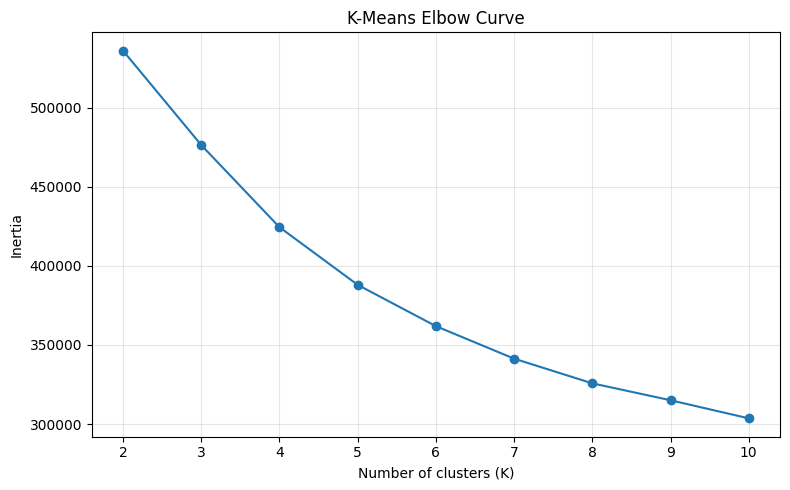

In [39]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Silhouette score

The silhouette coefficient compares how close an observation is to its own cluster relative to the nearest alternative cluster. Scores closer to 1 indicate better separation, values near 0 indicate overlapping clusters, and negative values can indicate poor assignments.

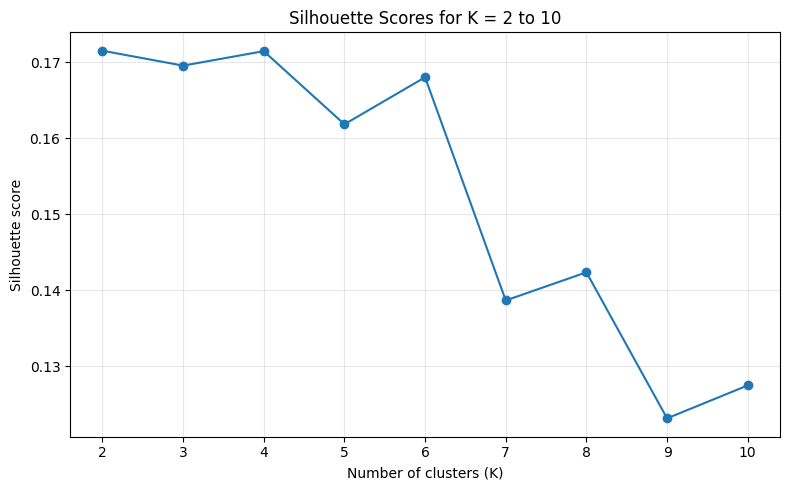

Highest silhouette score occurs at K=2 (0.1715).


In [40]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Scores for K = 2 to 10")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_silhouette_k = k_values[int(np.argmax(silhouette_scores))]
print(f"Highest silhouette score occurs at K={best_silhouette_k} ({max(silhouette_scores):.4f}).")

### Selecting the number of clusters

The final K is selected by considering both the elbow curve and silhouette scores. The highest silhouette score is a useful guide, but a low absolute score indicates that the groups overlap and should be treated as broad profiles rather than sharply separated customer types. The next cell selects the highest-silhouette candidate among the tested values; inspect the elbow curve and cluster sizes before finalising the interpretation.

In [41]:
final_k = best_silhouette_k
kmeans_final = KMeans(n_clusters=final_k, random_state=RANDOM_STATE, n_init=10)
df["cluster"] = kmeans_final.fit_predict(X_cluster)

cluster_sizes = df["cluster"].value_counts().sort_index().rename("booking_count")
display(cluster_sizes.to_frame())
print(f"Selected K={final_k}; silhouette={max(silhouette_scores):.4f}.")

,booking_count
cluster,
0,50249
1,36861


Selected K=2; silhouette=0.1715.


## 3.3 Cluster profiling and interpretation

Cluster means are calculated for key booking variables. The cancellation rate is included only as a post-clustering profile measure, not as an input to K-Means. This helps determine whether the booking groups show different observed cancellation patterns.

In [42]:
profile_columns = [
    "lead_time", "adr", "total_stay_nights", "total_guests",
    "previous_cancellations", "total_of_special_requests", "is_canceled"
]
cluster_profile = df.groupby("cluster")[profile_columns].mean()
cluster_profile["booking_count"] = df.groupby("cluster").size()
cluster_profile["cancellation_rate_percent"] = cluster_profile["is_canceled"] * 100
display(cluster_profile.drop(columns="is_canceled").round(2))

,lead_time,adr,total_stay_nights,total_guests,previous_cancellations,total_of_special_requests,booking_count,cancellation_rate_percent
cluster,,,,,,,,
0,40.98,86.77,2.62,1.74,0.04,0.44,50249,22.50
1,132.55,133.09,5.01,2.42,0.01,1.05,36861,33.79


### Plain-English cluster labels

Use the profile table to describe each cluster according to its observed characteristics. Avoid assigning labels such as “high-value” unless the ADR and stay-duration measures support that interpretation. The cancellation rate describes an association within each group; it does not show that cluster membership causes cancellation.

In [43]:
for cluster_id, row in cluster_profile.iterrows():
    print(
        f"Cluster {cluster_id}: {int(row['booking_count']):,} bookings; "
        f"mean lead time {row['lead_time']:.1f} days; "
        f"mean ADR {row['adr']:.2f}; "
        f"mean stay {row['total_stay_nights']:.2f} nights; "
        f"cancellation rate {row['cancellation_rate_percent']:.2f}%."
    )

Cluster 0: 50,249 bookings; mean lead time 41.0 days; mean ADR 86.77; mean stay 2.62 nights; cancellation rate 22.50%.
Cluster 1: 36,861 bookings; mean lead time 132.6 days; mean ADR 133.09; mean stay 5.01 nights; cancellation rate 33.79%.


## 3.4 PCA visualisation

Principal Component Analysis reduces the clustering feature space to two dimensions for visual inspection. Because the full encoded matrix may be sparse, PCA is applied to a manageable sample. The sample is densified only for this two-dimensional visualisation.

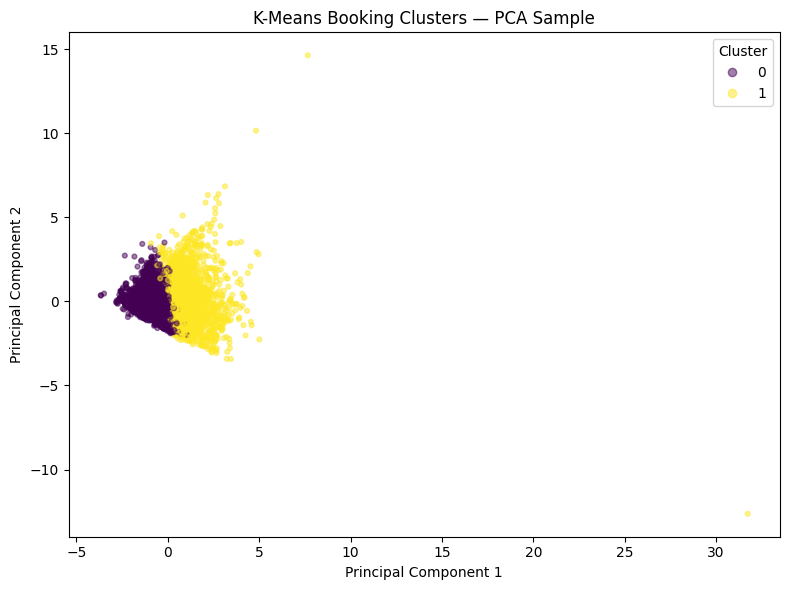

Variance explained by two components: 0.4357


In [44]:
from sklearn.decomposition import PCA

pca_size = min(5000, X_cluster.shape[0])
pca_indices = rng.choice(X_cluster.shape[0], size=pca_size, replace=False)
X_pca_source = X_cluster[pca_indices]
if sparse.issparse(X_pca_source):
    X_pca_source = X_pca_source.toarray()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_pca_source)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df.iloc[pca_indices]["cluster"], alpha=0.5, s=12
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Booking Clusters — PCA Sample")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()
print("Variance explained by two components:", round(pca.explained_variance_ratio_.sum(), 4))

# Part 4 — Classification

## 4.1 Define the prediction task and remove unsuitable predictors

The classification target is `is_canceled`. The predictors exclude the target, cluster label and known post-outcome leakage columns. `assigned_room_type` and `booking_changes` are also excluded because they may reflect changes made after the initial booking; their availability at the intended prediction time cannot be guaranteed from this dataset. This conservative choice makes the task closer to estimating cancellation risk from booking-time information.

In [45]:
target = "is_canceled"
additional_timing_exclusions = ["assigned_room_type", "booking_changes"]
excluded = [target, "cluster"] + additional_timing_exclusions
X = df.drop(columns=[c for c in excluded if c in df.columns])
y = df[target].astype(int)

# Verify that known leakage fields are not present.
for col in ["reservation_status", "reservation_status_date", "is_canceled", "cluster"]:
    assert col not in X.columns, f"Unexpected target/leakage field in predictors: {col}"

print("Predictor shape:", X.shape)
print("Target distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

Predictor shape: (87110, 29)
Target distribution:
is_canceled
0    72.72
1    27.28
Name: proportion, dtype: float64


## 4.2 Train, validation and test split

A stratified split is used to preserve the cancellation proportion across the training, validation and test sets. The training set fits models, the validation set supports model selection and threshold selection, and the test set is reserved for final performance reporting. This separation reduces the risk of choosing a model or threshold based on the final test results.

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
print("Cancellation rate — train/validation/test:",
      round(y_train.mean(), 3), round(y_valid.mean(), 3), round(y_test.mean(), 3))

Train: (52266, 29) Validation: (17422, 29) Test: (17422, 29)
Cancellation rate — train/validation/test: 0.273 0.273 0.273


## 4.3 Preprocessing pipeline

Numerical predictors are median-imputed and standardised. Categorical predictors are imputed with their most frequent category and one-hot encoded. The transformations are fitted within each model pipeline using the training data only. This prevents information from the validation or test sets from influencing preprocessing.

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical predictors:", len(numerical_features))
print("Categorical predictors:", len(categorical_features))

Numerical predictors: 19
Categorical predictors: 10


## 4.4 Baseline and model comparison

A stratified Dummy Classifier provides a simple baseline. Logistic Regression is included as an interpretable linear benchmark, while Decision Tree and Random Forest represent tree-based approaches capable of capturing nonlinear patterns. Models are compared on the validation set using accuracy, precision, recall, F1 and ROC-AUC. F1 is useful when both precision and recall matter; ROC-AUC measures ranking ability across thresholds.

In [48]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)


def make_model_pipeline(estimator):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

models = {
    "Stratified Dummy": make_model_pipeline(
        DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
    ),
    "Logistic Regression": make_model_pipeline(
        LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_model_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=10)
    ),
    "Random Forest": make_model_pipeline(
        RandomForestClassifier(
            n_estimators=200, random_state=RANDOM_STATE,
            n_jobs=-1, min_samples_leaf=2
        )
    )
}

validation_results = []
fitted_models = {}
for name, pipeline in models.items():
    print("Fitting", name)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_valid)
    prob = pipeline.predict_proba(X_valid)[:, 1]
    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_valid, prob)
    })
    fitted_models[name] = pipeline

validation_results = pd.DataFrame(validation_results).sort_values("F1", ascending=False)
display(validation_results.round(4))

Fitting Stratified Dummy


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Fitting Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Fitting Decision Tree


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Fitting Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC AUC
3,Random Forest,0.8280,0.7538,0.5484,0.6349,0.8869
2,Decision Tree,0.7973,0.6461,0.5682,0.6046,0.8337
1,Logistic Regression,0.7933,0.6700,0.4773,0.5575,0.8404
0,Stratified Dummy,0.6053,0.2738,0.2706,0.2722,0.5007


### Model comparison interpretation

Compare the validation metrics rather than relying on accuracy alone. A model with high accuracy can still miss many canceled bookings. The stratified dummy result is the baseline to beat. The selected model should offer a useful balance of precision and recall and should be judged against the hotel's operational cost of false alerts and missed cancellations.

# Part 5 — Imbalance Handling and Threshold Evaluation

## 5.1 Class weighting

The target has more non-canceled than canceled bookings. Class weighting is tested as an alternative to the unweighted Random Forest. It increases the penalty for errors on the cancellation class without creating synthetic records. Its usefulness is determined by comparing validation metrics, especially recall and F1, against the unweighted model.

In [49]:
balanced_rf = make_model_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    )
)
balanced_rf.fit(X_train, y_train)

balanced_prob_valid = balanced_rf.predict_proba(X_valid)[:, 1]
balanced_pred_valid = (balanced_prob_valid >= 0.5).astype(int)

balanced_metrics = {
    "Model": "Random Forest (balanced)",
    "Accuracy": accuracy_score(y_valid, balanced_pred_valid),
    "Precision": precision_score(y_valid, balanced_pred_valid, zero_division=0),
    "Recall": recall_score(y_valid, balanced_pred_valid, zero_division=0),
    "F1": f1_score(y_valid, balanced_pred_valid, zero_division=0),
    "ROC AUC": roc_auc_score(y_valid, balanced_prob_valid)
}

comparison_with_balanced = pd.concat([
    validation_results,
    pd.DataFrame([balanced_metrics])
], ignore_index=True).sort_values("F1", ascending=False)
display(comparison_with_balanced.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC AUC
4,Random Forest (balanced),0.8236,0.6571,0.7386,0.6955,0.8888
0,Random Forest,0.8280,0.7538,0.5484,0.6349,0.8869
1,Decision Tree,0.7973,0.6461,0.5682,0.6046,0.8337
2,Logistic Regression,0.7933,0.6700,0.4773,0.5575,0.8404
3,Stratified Dummy,0.6053,0.2738,0.2706,0.2722,0.5007


## 5.2 Select a model using validation performance

The model is selected using validation F1, with ROC-AUC and the precision-recall balance considered as supporting evidence. The balanced Random Forest is included in the same comparison. The test set remains untouched until the final evaluation.

In [50]:
candidate_pipelines = dict(fitted_models)
candidate_pipelines["Random Forest (balanced)"] = balanced_rf

candidate_f1 = comparison_with_balanced.set_index("Model")["F1"]
selected_model_name = candidate_f1.idxmax()
selected_model = candidate_pipelines[selected_model_name]
print("Selected model based on validation F1:", selected_model_name)
print("Validation F1:", round(float(candidate_f1.loc[selected_model_name]), 4))

Selected model based on validation F1: Random Forest (balanced)
Validation F1: 0.6955


## 5.3 Threshold tuning

The default classification threshold of 0.50 is not necessarily the best operational threshold. The precision-recall curve is used to select a threshold on the validation set. The example business objective is to achieve at least 70% recall for cancellations while maximising precision among thresholds that meet that target. This target is an analytical choice for the project, not a confirmed hotel policy. If no threshold reaches the target, the code selects the threshold with the highest validation F1.

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


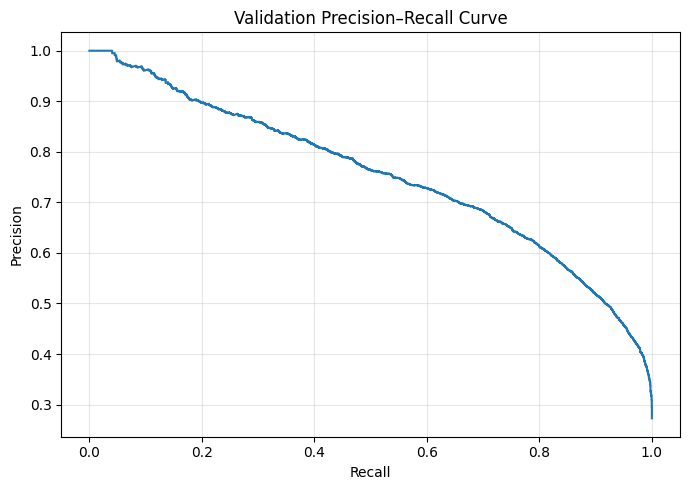

Selected threshold: 0.5293
Selection rule: Highest precision among thresholds achieving recall >= 70%
Validation precision: 0.6829
Validation recall: 0.7003


In [51]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

valid_prob = selected_model.predict_proba(X_valid)[:, 1]
precision_curve, recall_curve, thresholds = precision_recall_curve(y_valid, valid_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

TARGET_RECALL = 0.70
eligible = np.flatnonzero(recall_curve[:-1] >= TARGET_RECALL)

if len(eligible) > 0:
    chosen_idx = eligible[np.argmax(precision_curve[:-1][eligible])]
    threshold = float(thresholds[chosen_idx])
    threshold_selection_reason = f"Highest precision among thresholds achieving recall >= {TARGET_RECALL:.0%}"
else:
    f1_by_threshold = (
        2 * precision_curve[:-1] * recall_curve[:-1] /
        (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
    )
    chosen_idx = int(np.argmax(f1_by_threshold))
    threshold = float(thresholds[chosen_idx])
    threshold_selection_reason = "70% recall target not reached; selected threshold maximising validation F1"

print("Selected threshold:", round(threshold, 4))
print("Selection rule:", threshold_selection_reason)
print("Validation precision:", round(float(precision_curve[chosen_idx]), 4))
print("Validation recall:", round(float(recall_curve[chosen_idx]), 4))

## 5.4 Final test-set evaluation

After selecting the model and threshold using validation data, the model is evaluated once on the held-out test set. The final report includes threshold-based metrics, ROC-AUC, a confusion matrix and a classification report. These are the figures to use in the project summary and CV, subject to the limitations discussed in the conclusion.

In [52]:
test_prob = selected_model.predict_proba(X_test)[:, 1]
test_pred_default = (test_prob >= 0.50).astype(int)
test_pred_tuned = (test_prob >= threshold).astype(int)

final_metrics = {
    "Model": selected_model_name,
    "Threshold": threshold,
    "Accuracy": accuracy_score(y_test, test_pred_tuned),
    "Precision": precision_score(y_test, test_pred_tuned, zero_division=0),
    "Recall": recall_score(y_test, test_pred_tuned, zero_division=0),
    "F1": f1_score(y_test, test_pred_tuned, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, test_prob)
}

print("Final test-set metrics at tuned threshold")
display(pd.DataFrame([final_metrics]).round(4))
print("Confusion matrix (rows = actual, columns = predicted):")
cm = confusion_matrix(y_test, test_pred_tuned)
display(pd.DataFrame(
    cm,
    index=["Actual not canceled", "Actual canceled"],
    columns=["Predicted not canceled", "Predicted canceled"]
))
print("Classification report:")
print(classification_report(y_test, test_pred_tuned, zero_division=0))

print("Default 0.50 threshold F1:", round(f1_score(y_test, test_pred_default), 4))
print("Tuned threshold F1:", round(f1_score(y_test, test_pred_tuned), 4))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Final test-set metrics at tuned threshold


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest (balanced),0.5293,0.8342,0.6943,0.7008,0.6975,0.8921


Confusion matrix (rows = actual, columns = predicted):


,Predicted not canceled,Predicted canceled
Actual not canceled,11204,1466
Actual canceled,1422,3330


Classification report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89     12670
           1       0.69      0.70      0.70      4752

    accuracy                           0.83     17422
   macro avg       0.79      0.79      0.79     17422
weighted avg       0.83      0.83      0.83     17422

Default 0.50 threshold F1: 0.701
Tuned threshold F1: 0.6975


### Evaluation interpretation

Precision measures the proportion of flagged bookings that actually cancel. Recall measures the proportion of all canceled bookings identified by the model. A lower threshold usually increases recall but may also increase false alerts. The appropriate threshold should ultimately be chosen using the hotel's costs of missed cancellations, customer contact and overbooking. The project threshold is a transparent validation-based demonstration, not a production policy.

# Part 6 — The Tie-in: Connect Clusters and Cancellation

The clustering and classification analyses address complementary questions. Clustering groups bookings by their characteristics without using the cancellation outcome. Cancellation rates are then compared across those groups to see whether the naturally occurring profiles have different observed outcomes. The classification model separately estimates cancellation risk at booking level. The cluster label is not used as a classification predictor, avoiding the use of an outcome-informed segmentation label as a shortcut.

In [53]:
cluster_cancellation = (
    df.groupby("cluster")["is_canceled"]
      .agg(booking_count="size", cancellation_rate="mean")
)
cluster_cancellation["cancellation_rate_percent"] = cluster_cancellation["cancellation_rate"] * 100
display(cluster_cancellation.drop(columns="cancellation_rate").round(2))

highest_risk_cluster = cluster_cancellation["cancellation_rate"].idxmax()
lowest_risk_cluster = cluster_cancellation["cancellation_rate"].idxmin()
print(
    f"Cluster {highest_risk_cluster} has the highest observed cancellation rate "
    f"({cluster_cancellation.loc[highest_risk_cluster, 'cancellation_rate_percent']:.2f}%)."
)
print(
    f"Cluster {lowest_risk_cluster} has the lowest observed cancellation rate "
    f"({cluster_cancellation.loc[lowest_risk_cluster, 'cancellation_rate_percent']:.2f}%)."
)

,booking_count,cancellation_rate_percent
cluster,,
0,50249,22.50
1,36861,33.79


Cluster 1 has the highest observed cancellation rate (33.79%).
Cluster 0 has the lowest observed cancellation rate (22.50%).


### Interpretation

Use the cluster profile and cancellation-rate table together. The cluster with the higher cancellation rate is a useful group for further monitoring, while the lower-rate cluster may provide a more predictable baseline for planning. These are historical associations, not causal effects. A hotel should validate the profiles on more recent bookings before using them to change deposit, pricing or customer-contact policies.

# Part 7 — Conclusion and Business Recommendations

## 7.1 Key findings

The SQL analysis shows that cancellation exposure differs across hotel types, market segments and deposit categories. The clustering analysis identifies broad booking profiles and compares their observed cancellation rates. Classification models are compared on a validation set, and the selected model is evaluated on a separate test set using a threshold selected without using test outcomes.

The executed output tables above provide the final numerical findings. The conclusions should be written from those rerun outputs rather than from previous notebook versions.

## 7.2 Business recommendations

1. **Prioritise group-booking review:** The source-data SQL analysis reports a 61.06% cancellation rate for the Groups segment across 19,811 bookings. Review group booking terms, confirmation processes and cancellation reasons before changing policy.
2. **Investigate City Hotel exposure:** City Hotel's observed cancellation rate is higher than Resort Hotel's. Compare booking mix, lead time, channel and customer type to identify operational drivers.
3. **Use booking profiles for targeted monitoring:** Use the higher-cancellation cluster as a monitoring cohort for timely confirmation and reminder workflows. Avoid assuming every booking in the group will cancel.
4. **Use risk estimates to support planning:** Combine predicted cancellation probabilities with booking volume and stay duration to support room allocation and staffing decisions. Do not use predictions as automatic grounds for penalties or customer restrictions.
5. **Validate unusual deposit findings:** The Non Refund category's very high observed cancellation rate should be checked against source records and category definitions before any deposit-policy recommendation is made.

## 7.3 Limitations and responsible use

- The dataset is historical and may not represent current booking behaviour, hotel policies or market conditions.
- The project uses a random stratified test split. A future time-based evaluation would provide stronger evidence of performance on later bookings.
- Some variables may be recorded or updated at different points in the booking lifecycle. The model excludes known post-outcome fields and selected potentially post-booking fields, but the exact timestamp availability of every predictor cannot be established from the dataset alone.
- Cancellation rates are descriptive associations and do not establish causation.
- The estimated stay value is an ADR-based proxy, not actual revenue.
- Model performance does not establish business value. A pilot should measure saved room nights, avoided empty rooms, customer-contact costs and false-alert rates before deployment.
- Predictions should support staff decisions and should not automatically trigger punitive customer treatment.

## 7.4 Final conclusion

This project demonstrates an end-to-end analytical workflow using Python, Pandas, SQLite, exploratory data analysis, feature engineering, clustering and classification. The most useful business outcome is a structured way to identify where cancellations are concentrated, understand broad booking profiles and prioritise bookings for further review. Before operational deployment, the selected model requires time-based validation, monitoring for changes in booking patterns and a cost-based decision on the appropriate probability threshold.

# Depth Track

## Clustering depth

The clustering depth work evaluates K from 2 to 10 using inertia and sampled silhouette scores, profiles the selected clusters and visualises the feature space using PCA. The silhouette score should be interpreted alongside the elbow curve and cluster sizes. A low silhouette score signals overlapping profiles and limits how strongly the groups should be treated as distinct segments.

## Classification depth

The classification depth work compares a Dummy Classifier, Logistic Regression, Decision Tree and Random Forest using validation metrics. A separate test set is used for final evaluation. The notebook also excludes the target, cluster labels and known or potentially post-booking variables from the predictors to reduce leakage risk.

## Imbalance depth

Class weighting is evaluated against the unweighted Random Forest. Threshold tuning is conducted using validation precision-recall results, with a stated recall objective. Final test-set metrics are reported only after model and threshold selection. This makes the precision-recall trade-off explicit rather than selecting an arbitrary threshold.

## Final reproducibility and summary check

The final cell prints the cleaned dataset dimensions, selected model, threshold, test metrics, stratified dummy baseline and elapsed runtime. Re-run all cells from the top in a fresh Colab session before submission. Confirm that every code cell executes without errors and that all narrative interpretations match the generated tables.

In [54]:
# Final submission summary generated from the executed notebook.
final_summary = pd.DataFrame([
    {"Item": "Group Number", "Entry": "40"},
    {"Item": "Full Name", "Entry": "Itunuoluwa Michael Akanmu"},
    {"Item": "Dataset", "Entry": "Hotel Booking Demand / Hotel Booking Cancellations"},
    {"Item": "Depth Track", "Entry": "Clustering, classification and imbalance evaluation"},
    {"Item": "Cleaned Dataset Rows", "Entry": f"{len(df):,}"},
    {"Item": "Final Model", "Entry": selected_model_name},
    {"Item": "Final Threshold", "Entry": f"{threshold:.4f}"},
    {"Item": "Final Test F1", "Entry": f"{final_metrics['F1']:.4f}"},
    {"Item": "Final Test ROC AUC", "Entry": f"{final_metrics['ROC AUC']:.4f}"},
    {"Item": "Stratified Dummy Validation F1", "Entry": f"{float(validation_results.loc[validation_results['Model'] == 'Stratified Dummy', 'F1'].iloc[0]):.4f}"},
    {"Item": "Stratified Dummy Validation ROC AUC", "Entry": f"{float(validation_results.loc[validation_results['Model'] == 'Stratified Dummy', 'ROC AUC'].iloc[0]):.4f}"},
    {"Item": "Leakage Columns Excluded", "Entry": "reservation_status; reservation_status_date"},
    {"Item": "Elapsed Runtime (minutes)", "Entry": f"{(time.perf_counter() - run_start) / 60:.2f}"}
])
display(final_summary)

# Close SQLite connection after all SQL analysis is complete.
conn.close()
print("Notebook workflow completed successfully.")

,Item,Entry
0,Group Number,40
1,Full Name,Itunuoluwa Michael Akanmu
2,Dataset,Hotel Booking Demand / Hotel Booking Cancellat...
3,Depth Track,"Clustering, classification and imbalance evalu..."
4,Cleaned Dataset Rows,"87,110"
5,Final Model,Random Forest (balanced)
6,Final Threshold,0.5293
7,Final Test F1,0.6975
8,Final Test ROC AUC,0.8921
9,Stratified Dummy Validation F1,0.2722


Notebook workflow completed successfully.
